# Lösungen

[&larr; Einführung](01_FFT.ipynb)

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft, signal, io

## Übung 1

a) $y(t) = 0.6 \cdot \cos\left(2\pi \cdot 5 \cdot t + \frac{\pi}{5}\right)$ 

b) $y(t) = 4 \cdot \cos\left(2\pi \cdot 12 \cdot t - \frac{\pi}{4}\right)$ 

c) $y(t) = 2 \cdot \cos\left(2\pi \cdot 4 \cdot t\right) + 2$ 


## Übung 2

a)

In [39]:
fs, signal_raw = io.wavfile.read('data/tone.wav')

b)

In [40]:
fmax = fs/2  # Nyquist-Frequenz [Hz]
print('Maximale Frequenz im Spektrum = {:.0f} Hz (Abtastfrequenz = {:.0f} Hz)'.format(fmax, fs))

Maximale Frequenz im Spektrum = 22050 Hz (Abtastfrequenz = 44100 Hz)


c)

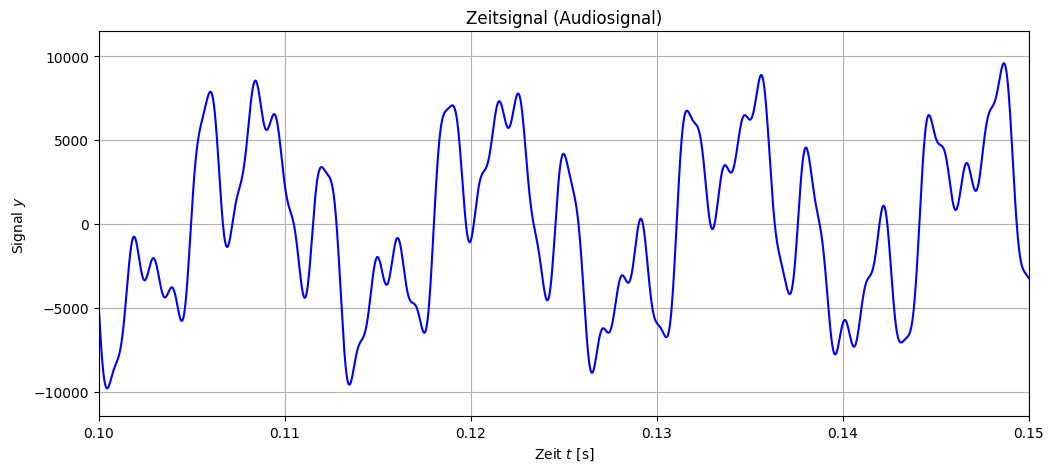

In [42]:
t = np.arange(0, len(signal_raw)) * 1/fs  # Zeitarray [s]

plt.figure(figsize=(12, 5))
plt.plot(t, signal_raw, 'b')
plt.title('Zeitsignal (Audiosignal)')
plt.xlabel('Zeit $t$ [s]')
plt.ylabel('Signal $y$')
plt.grid()
plt.xlim([0.1, 0.15])  # Achsenbegrenzungen
plt.show()

d)

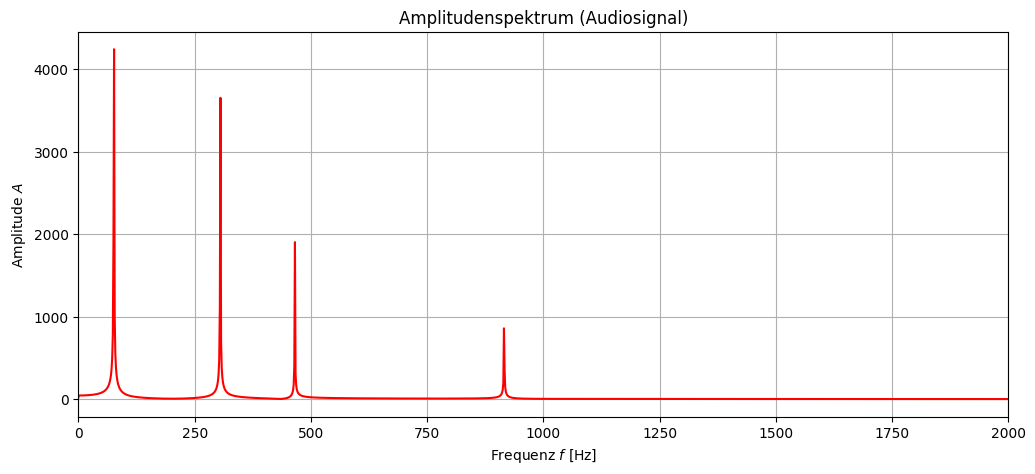

In [43]:
N = len(signal_raw)  # Anzahl Samples

Y = fft.rfft(signal_raw)/N  # DFT berechnen
A = abs(Y)  # Amplituden
A[1:] *= 2  # Amplituden skalieren
f = fft.rfftfreq(N, 1/fs)  # Frequenzachse erzeugen

plt.figure(figsize=(12, 5))
plt.plot(f, A, 'r')
plt.title('Amplitudenspektrum (Audiosignal)')
plt.xlabel('Frequenz $f$ [Hz]')
plt.ylabel('Amplitude $A$')
plt.xlim([0, 2000])
plt.grid()
plt.show()

e)

In [44]:
# hier mit Funktion find_peaks() aus SciPy, alternativ direkt aus obigem Diagramm ablesen
inds = signal.find_peaks(A, height=500)[0]
for ind in inds:
    print('Frequenzpeak bei {:.0f} Hz'.format(f[ind]))

Frequenzpeak bei 77 Hz
Frequenzpeak bei 306 Hz
Frequenzpeak bei 466 Hz
Frequenzpeak bei 915 Hz


## Übung 3

a)

In [45]:
y = np.loadtxt('data/UEBUNG.TXT', skiprows=1)  # TXT-File importieren
fs = 2560  # Abtastfrequenz [Hz]
N = len(y)  # Anzahl Samples

b)

In [46]:
# Fensterung
w = signal.windows.get_window('tukey', N)  # Fensterfunktion
y_w = w * (y - y.mean()) + y.mean()  # Fensterfunktion auf Signal anwenden (Offset für Fensterung entfernen)

# Spektrum berechnen
Y = fft.rfft(y_w)/N  # Fourier-Transformation berechnen
A = abs(Y)  # Amplituden bestimmen
A[1:] *= 2  # Amplituden (ausser DC-Anteil) verdoppeln
f = fft.rfftfreq(N, 1/fs)  # Frequenzachse erstellen

c)

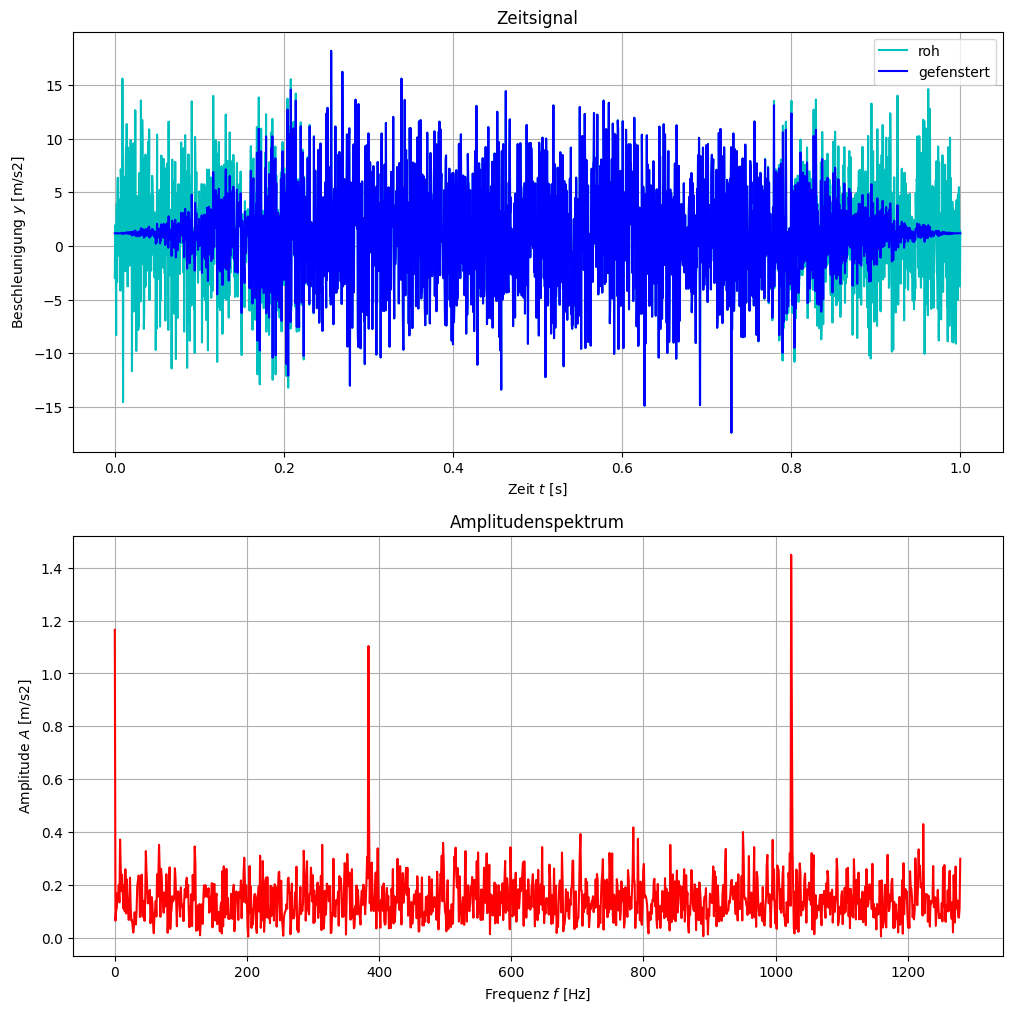

In [47]:
t = np.arange(0, len(y)) * 1/fs  # Zeitarray [s]

fig, axs = plt.subplots(2, 1, figsize=(12, 12))  # Subfigure mit 2 Plots übereinander
axs[0].plot(t, y, 'c', label='roh')
axs[0].plot(t, y_w, 'b', label='gefenstert')  # zusätzlich gefenstertes Signal (nicht explizit gefragt in Aufgabenstellung)
axs[0].set_xlabel('Zeit $t$ [s]')
axs[0].set_ylabel('Beschleunigung $y$ [m/s2]')
axs[0].set_title('Zeitsignal')
axs[0].grid()
axs[0].legend()
axs[1].plot(f, A, 'r')
axs[1].set_xlabel('Frequenz $f$ [Hz]')
axs[1].set_ylabel('Amplitude $A$ [m/s2]')
axs[1].set_title('Amplitudenspektrum')
axs[1].grid()
plt.show()

## Übung 4

a)

In [48]:
y_DC = 7.25  # Gleichanteil
y_1 = 1.25  # Amplitude 1. Schwingung
f_1 = 87  # Frequenz 1. Schwingung
y_2 = 0.75  # Amplitude 2. Schwingung
f_2 = 167  # Frequenz 2. Schwingung
y_r = 0.5  # Rauschamplitude

fs = 10 * max(f_1, f_2)  # Abtastfrequenz [Hz]
N = 5 * fs  # Anzahl Samples
t = np.arange(0, N) * 1/fs  # Zeitarray

y = y_DC + y_1 * np.sin(2*np.pi*f_1*t) + y_2 * np.sin(2*np.pi*f_2*t) + y_r * np.random.randn(N)

b)

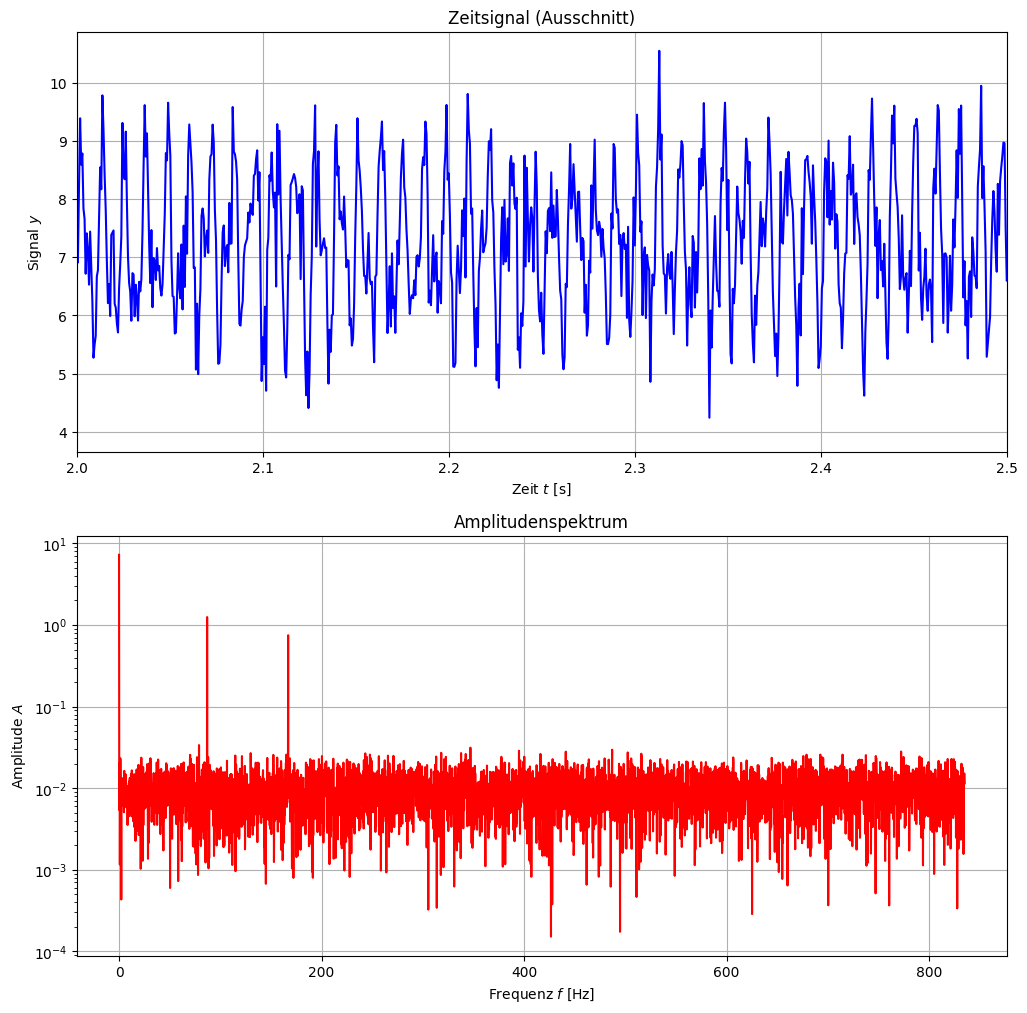

In [49]:
Y = fft.rfft(y)/N  # Fourier-Transformation berechnen
A = abs(Y)  # Amplituden bestimmen
A[1:] *= 2  # Amplituden (ausser DC-Anteil) skalieren
f = fft.rfftfreq(N, 1/fs)  # Frequenzachse erstellen

fig, axs = plt.subplots(2, 1, figsize=(12, 12))  # Subfigure mit 2 Plots übereinander
axs[0].plot(t, y, 'b')
axs[0].set_xlabel('Zeit $t$ [s]')
axs[0].set_ylabel('Signal $y$')
axs[0].set_title('Zeitsignal (Ausschnitt)')
axs[0].grid()
axs[0].set_xlim([2, 2.5])
axs[1].plot(f, A, 'r')
axs[1].set_yscale('log')  # alternativ semilogy() anstatt plot()
axs[1].set_xlabel('Frequenz $f$ [Hz]')
axs[1].set_ylabel('Amplitude $A$')
axs[1].set_title('Amplitudenspektrum')
axs[1].grid()
plt.show()

## Übung 5

- Frequenzachse geht bis $f_S/2$, d. h. 75 Hz
- Gleichanteil: Amplitude ca. 2 V
- Grundschwingung: Amplitude ca. 1 V und Frequenz ca. 5 Hz (~ 5 Peaks in 1 s)
- Oberschwingung: Amplitude ca. 0.5 V und Frequenz ca. 50 Hz (~ 50 Peaks in 1 s)

<center>
    <img src="img/FA_U5_LSG.svg" />
</center>


## Übung 6

Lösung: b)
- Gleichanteil: Amplitude ca. 2 V
- Grundschwingung: Amplitude ca. 2 V und Frequenz ca. 3 Hz
- Oberschwingung: Amplitude ca. 1 V und Frequenz ca. 12 Hz (24 Peaks in 2 s)